In [1]:
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn import metrics

# %matplotlib_widget
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('bitcoin (1).csv')
df.head() 

,Date,Close,High,Low,Open,Volume
0,2014-09-17,457.334015,468.174011,452.421997,465.864014,21056800
1,2014-09-18,424.440002,456.859985,413.104004,456.859985,34483200
2,2014-09-19,394.795990,427.834991,384.532013,424.102997,37919700
3,2014-09-20,408.903992,423.295990,389.882996,394.673004,36863600
4,2014-09-21,398.821014,412.425995,393.181000,408.084991,26580100


In [3]:
df.shape

(4134, 6)

In [4]:
df.describe()

,Close,High,Low,Open,Volume
count,4134.000000,4134.000000,4134.000000,4134.000000,4.134000e+03
mean,27003.890261,27524.788487,26411.358297,26983.157505,2.166430e+10
std,31769.798188,32299.170829,31181.581319,31757.880659,2.287787e+10
min,178.102997,211.731003,171.509995,176.897003,5.914570e+06
25%,2717.330017,2787.382568,2646.232544,2709.462463,1.318940e+09
50%,10795.145508,11050.480957,10497.678711,10796.618652,1.711303e+10
75%,42371.426758,43187.265625,41541.421875,42343.803711,3.322487e+10
max,124752.531250,126198.070312,123196.046875,124752.140625,3.509679e+11


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4134 entries, 0 to 4133
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    4134 non-null   str    
 1   Close   4134 non-null   float64
 2   High    4134 non-null   float64
 3   Low     4134 non-null   float64
 4   Open    4134 non-null   float64
 5   Volume  4134 non-null   int64  
dtypes: float64(4), int64(1), str(1)
memory usage: 193.9 KB


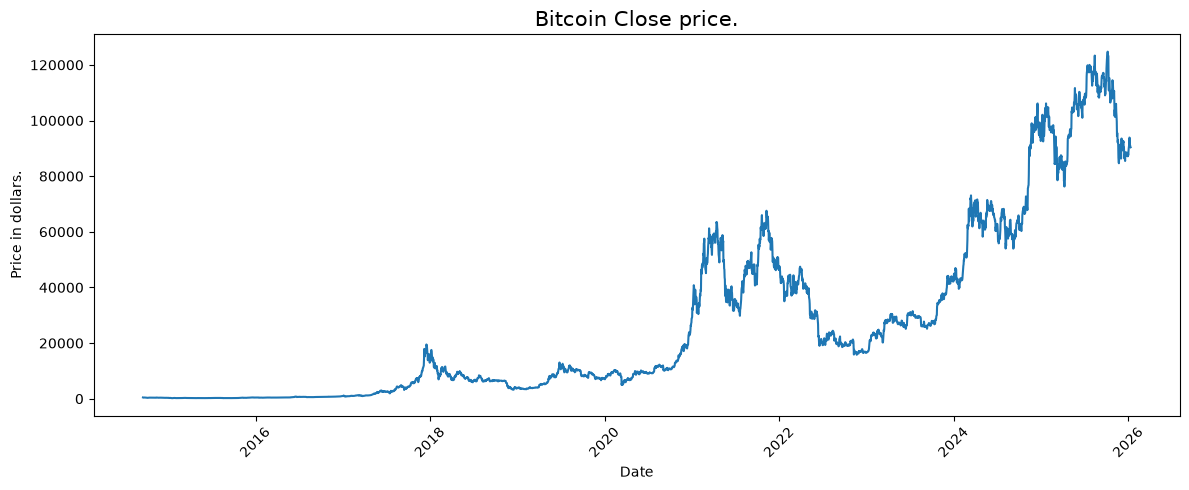

In [ ]:
plt.close()
plt.figure(figsize=(12, 5))
plt.plot(pd.to_datetime(df['Date']), df['Close'])
plt.title('Bitcoin Close price.', fontsize=15)
plt.xlabel('Date')
plt.ylabel('Price in dollars.')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
df.isnull().sum()

Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

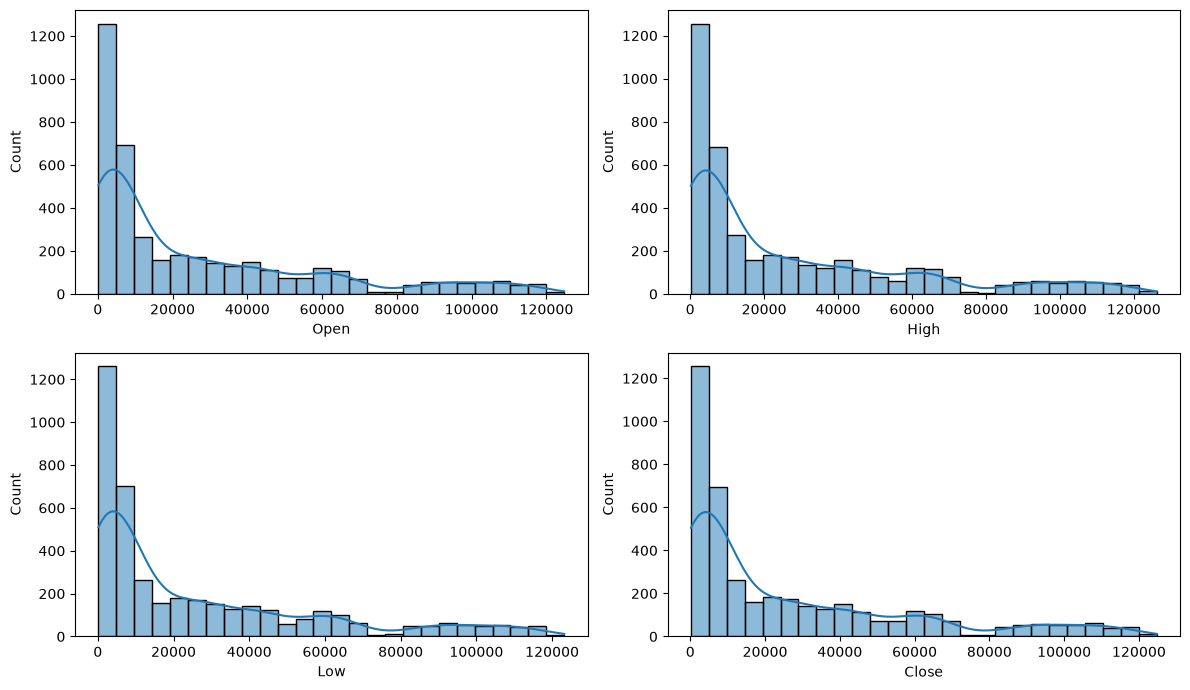

In [9]:
features = ['Open', 'High', 'Low', 'Close']
plt.close()
plt.figure(figsize=(12,7))
for i, col in enumerate(features):
  plt.subplot(2,2,i+1)
  sb.histplot(df[col], kde=True)
plt.tight_layout()
plt.show()

In [10]:
splitted = df['Date'].str.split('-', expand=True)
 
df['year'] = splitted[0].astype('int')
df['month'] = splitted[1].astype('int')
df['day'] = splitted[2].astype('int')
 
df.head()

,Date,Close,High,Low,Open,Volume,year,month,day
0,2014-09-17,457.334015,468.174011,452.421997,465.864014,21056800,2014,9,17
1,2014-09-18,424.440002,456.859985,413.104004,456.859985,34483200,2014,9,18
2,2014-09-19,394.795990,427.834991,384.532013,424.102997,37919700,2014,9,19
3,2014-09-20,408.903992,423.295990,389.882996,394.673004,36863600,2014,9,20
4,2014-09-21,398.821014,412.425995,393.181000,408.084991,26580100,2014,9,21


In [11]:
print(df.dtypes)

Date          str
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
year        int64
month       int64
day         int64
dtype: object


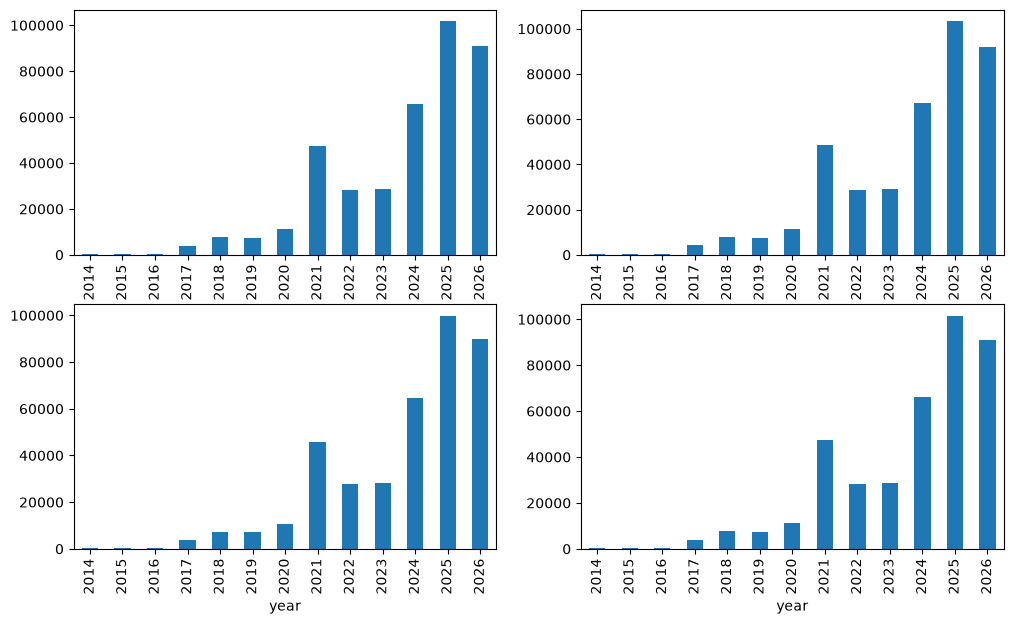

In [12]:
plt.close()
data_grouped = df.groupby('year').mean(numeric_only=True)
plt.figure(figsize=(12,7))
for i, col in enumerate(['Open', 'High', 'Low', 'Close']):
  plt.subplot(2,2,i+1)
  data_grouped[col].plot.bar()
plt.show()

In [13]:
df['is_quarter_end'] = (
    pd.to_datetime(df['Date']).dt.is_quarter_end.astype(int)
)
df.head()

,Date,Close,High,Low,Open,Volume,year,month,day,is_quarter_end
0,2014-09-17,457.334015,468.174011,452.421997,465.864014,21056800,2014,9,17,0
1,2014-09-18,424.440002,456.859985,413.104004,456.859985,34483200,2014,9,18,0
2,2014-09-19,394.795990,427.834991,384.532013,424.102997,37919700,2014,9,19,0
3,2014-09-20,408.903992,423.295990,389.882996,394.673004,36863600,2014,9,20,0
4,2014-09-21,398.821014,412.425995,393.181000,408.084991,26580100,2014,9,21,0


In [14]:
df['open-close']  = df['Open'] - df['Close']
df['low-high']  = df['Low'] - df['High']

# 1 = next closing price is higher
# 0 = next closing price is not higher
df['target'] = np.where(df['Close'].shift(-1) > df['Close'], 1, 0)

In [15]:
df = df.iloc[:-1].copy()
target_counts = df['target'].value_counts().reindex([0, 1], fill_value=0)

In [16]:
df['target'][1]

np.int64(0)

In [17]:
print(df['Close'][1],df['Close'].shift(-1)[1])

424.4400024414063 394.7959899902344


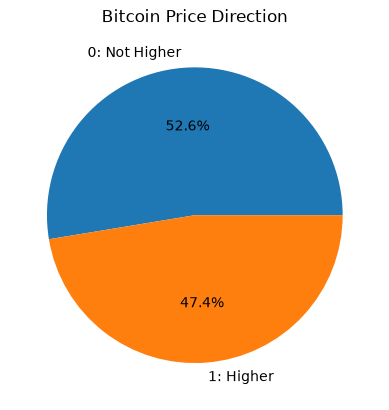

In [18]:
plt.close()
plt.pie(df['target'].value_counts().values,
        labels=['0: Not Higher', '1: Higher'],
        autopct='%1.1f%%')
plt.title('Bitcoin Price Direction')
plt.show()

In [19]:
features = df[['open-close', 'low-high', 'is_quarter_end']]
target = df['target']

In [20]:
split_idx = int(len(features) * 0.85)

X_train = features.iloc[:split_idx - 1]
X_valid = features.iloc[split_idx:]

Y_train = target.iloc[:split_idx - 1]
Y_valid = target.iloc[split_idx:]

print(X_train.shape, X_valid.shape)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)

(3512, 3) (620, 3)


In [21]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=10000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier()
}

for name, model in models.items():
    model.fit(X_train, Y_train)

    train_scores = model.predict_proba(X_train)[:, 1]
    valid_scores = model.predict_proba(X_valid)[:, 1]

    print(f"\n{name}")
    print(
        "Training ROC-AUC:",
        round(metrics.roc_auc_score(Y_train, train_scores), 4)
    )
    print(
        "Validation ROC-AUC:",
        round(metrics.roc_auc_score(Y_valid, valid_scores), 4)
    )


Logistic Regression
Training ROC-AUC: 0.5353
Validation ROC-AUC: 0.5211

Decision Tree
Training ROC-AUC: 1.0
Validation ROC-AUC: 0.4985

KNN
Training ROC-AUC: 0.7402
Validation ROC-AUC: 0.5055
